# E5 — Text-Defined Object Replacement: remove first, then insert

**What went wrong in E2-A:** Stable Diffusion was run directly over the original object. The old object leaked through, and the prompt had to fight a car-shaped hole.

**What E5 does instead:** it always **removes the object with MI-GAN first** (from E3), then inserts the new object into a *box-shaped* region of the clean background.

| Variant | Insert step | Text-defined? | Diffusion |
|---|---|---|---|
| **E5-A** | cutout compositing: asset library + colour match + contact shadow | no, library only | none |
| **E5-B** | SD-1.5-inpainting, DPM-Solver, 10 steps, CFG 7.5 | yes | baseline |
| **E5-C** | + LCM-LoRA, 4 steps, CFG 1.0 (a single UNet pass per step) | yes | distilled |
| **E5-D** | + TAESD tiny VAE (~2.4 M params in place of 84 M) | yes | distilled + tiny VAE |

**Shared stages:** regex parse → YOLOv8n → MobileSAM → MI-GAN removal. Each variant only changes the insert step.

**Quality metric:** CLIP ViT-B/32 zero-shot probability that the edited region shows the **target**, compared with the **old object** and an **empty background**. CLIP is used for evaluation only. It isn't part of the pipeline and isn't counted in its size.

⏱️ Runtime on 2-vCPU Colab is about 30–45 min, mostly E5-B. Shorten `BASELINE_CASES` if you need it faster.

> If Colab asks you to **restart the runtime** after the install cell, restart it, then run everything from the imports cell onward.

In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
!pip install -q -U ultralytics onnxruntime
!pip install -q git+https://github.com/ChaoningZhang/MobileSAM.git

# Same pinned set that worked in E3 (diffusers 0.40 needs huggingface-hub >= 1.23; optimum downgrades it)
!pip uninstall -y -q optimum optimum-onnx
!pip install -q -U "diffusers==0.40.0" "transformers>=4.41.2,<6" "accelerate>=1.1.0" "safetensors>=0.8.0" "peft>=0.20.0" "huggingface-hub>=1.23.0,<2.0"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 35.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.6/23.6 MB 45.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.1/91.1 kB 4.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 16.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 34.5 MB/s eta 0:00:00


In [3]:
import os
import re
import gc
import sys
import json
import time
import glob
import platform
import subprocess
import threading
import warnings
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil
import torch
from PIL import Image

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

import ultralytics
from ultralytics import YOLO
from mobile_sam import sam_model_registry, SamPredictor
import onnxruntime as ort

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)
print("ONNX Runtime:", ort.__version__)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Python: 3.13.15
PyTorch: 2.11.0+cpu
Ultralytics: 8.4.166
ONNX Runtime: 1.30.0


In [4]:
BASE_DIR = "/content/drive/MyDrive/inter_IIT/Task_2/"
IMAGE_DIR = BASE_DIR
ASSET_DIR = os.path.join(BASE_DIR, "assets")
MODEL_DIR = os.path.join(BASE_DIR, "models")
BENCHMARK_DIR = os.path.join(BASE_DIR, "benchmarks")
RESULTS_DIR = os.path.join(BASE_DIR, "results", "E5")

for d in [MODEL_DIR, BENCHMARK_DIR, RESULTS_DIR]:
    os.makedirs(d, exist_ok=True)

DEVICE = "cpu"
# E0-E3 used cpu_count() // 2 (= 1 thread on 2-vCPU Colab). Use every core.
CPU_THREADS = os.cpu_count() or 2
torch.set_num_threads(CPU_THREADS)
cv2.setNumThreads(CPU_THREADS)
SEED = 42


def cpu_model_name():
    try:
        with open("/proc/cpuinfo") as f:
            for line in f:
                if line.startswith("model name"):
                    return line.split(":", 1)[1].strip()
    except OSError:
        pass
    return platform.processor()


SYSTEM_INFO = {
    "cpu": cpu_model_name(),
    "logical_cores": os.cpu_count(),
    "threads_used": CPU_THREADS,
    "ram_gb": round(psutil.virtual_memory().total / 2**30, 2),
    "python": platform.python_version(),
    "torch": torch.__version__,
    "onnxruntime": ort.__version__,
    "opencv": cv2.__version__,
    "ultralytics": ultralytics.__version__,
}
print(json.dumps(SYSTEM_INFO, indent=2))

with open(os.path.join(BENCHMARK_DIR, "e5_system_info.json"), "w") as f:
    json.dump(SYSTEM_INFO, f, indent=2)

{
  "cpu": "Intel(R) Xeon(R) CPU @ 2.20GHz",
  "logical_cores": 2,
  "threads_used": 2,
  "ram_gb": 12.67,
  "python": "3.13.15",
  "torch": "2.11.0+cpu",
  "onnxruntime": "1.30.0",
  "opencv": "4.14.0",
  "ultralytics": "8.4.166"
}


In [5]:
def file_mb(path):
    return os.path.getsize(path) / 2**20


def params_m(module):
    return sum(p.numel() for p in module.parameters()) / 1e6


def fp32_mb(module):
    """In-memory fp32 weight size (params x 4 bytes)."""
    return sum(p.numel() for p in module.parameters()) * 4 / 2**20


def rss_mb():
    return psutil.Process().memory_info().rss / 2**20


def read_image(name):
    path = name if os.path.isabs(name) else os.path.join(IMAGE_DIR, name)
    img = cv2.imread(path)
    if img is None:  # some test images are AVIF files saved as .jpg
        img = cv2.cvtColor(np.array(Image.open(path).convert("RGB")), cv2.COLOR_RGB2BGR)
    return img


def to_rgb(img):
    return img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def slug(text, n=40):
    return re.sub(r"[^a-z0-9]+", "_", text.lower()).strip("_")[:n]


def save_image(img, name):
    path = os.path.join(RESULTS_DIR, name)
    cv2.imwrite(path, img)
    return path


def show_grid(rows, col_titles, row_titles=None, cell=4.0, save_as=None):
    """rows: list of lists of BGR images / masks / None."""
    nr, nc = len(rows), len(col_titles)
    fig, axes = plt.subplots(nr, nc, figsize=(cell * nc, cell * 0.75 * nr), squeeze=False)
    for r, row in enumerate(rows):
        for c in range(nc):
            ax = axes[r][c]
            ax.axis("off")
            img = row[c] if c < len(row) else None
            title = col_titles[c]
            if row_titles and c == 0:
                title = f"{row_titles[r]}\n{title}"
            ax.set_title(title, fontsize=9)
            if img is None:
                ax.text(0.5, 0.5, "N/A", ha="center", va="center", fontsize=14, transform=ax.transAxes)
                continue
            ax.imshow(to_rgb(img), cmap="gray" if img.ndim == 2 else None)
    plt.tight_layout()
    if save_as:
        fig.savefig(os.path.join(RESULTS_DIR, save_as), dpi=110, bbox_inches="tight")
    plt.show()


def time_it(fn, n=3):
    """Median latency (s) after one warm-up call."""
    fn()
    times = []
    for _ in range(n):
        t0 = time.perf_counter()
        fn()
        times.append(time.perf_counter() - t0)
    return float(np.median(times))


LOAD_STATS = []


def log_load(name, rss_before, size_mb=None, params=None):
    added = rss_mb() - rss_before
    LOAD_STATS.append({"component": name, "size_MB": size_mb, "params_M": params, "ram_added_MB": added})
    size_s = "?" if size_mb is None else f"{size_mb:.2f}"
    params_s = "?" if params is None else f"{params:.2f}"
    print(f"{name}: size={size_s} MB | params={params_s} M | +RAM={added:.0f} MB")

## Models

In [6]:
r0 = rss_mb()
YOLO_MODEL_NAME = "yolov8n.pt"
yolo_model = YOLO(YOLO_MODEL_NAME)
YOLO_SIZE_MB = file_mb(getattr(yolo_model, "ckpt_path", None) or YOLO_MODEL_NAME)
COCO_NAMES = [yolo_model.names[i].lower() for i in range(len(yolo_model.names))]
log_load("YOLOv8n", r0, YOLO_SIZE_MB, params_m(yolo_model.model))

r0 = rss_mb()
MOBILE_SAM_PATH = os.path.join(MODEL_DIR, "mobile_sam.pt")
if not os.path.exists(MOBILE_SAM_PATH):
    subprocess.run(
        ["wget", "-q", "https://github.com/ChaoningZhang/MobileSAM/raw/master/weights/mobile_sam.pt",
         "-O", MOBILE_SAM_PATH],
        check=True,
    )
mobile_sam = sam_model_registry["vit_t"](checkpoint=MOBILE_SAM_PATH)
mobile_sam.to(DEVICE)
mobile_sam.eval()
predictor = SamPredictor(mobile_sam)
MOBILE_SAM_SIZE_MB = file_mb(MOBILE_SAM_PATH)
log_load("MobileSAM", r0, MOBILE_SAM_SIZE_MB, params_m(mobile_sam))

YOLOv8n: size=6.25 MB | params=3.16 M | +RAM=18 MB
MobileSAM: size=38.84 MB | params=10.13 M | +RAM=90 MB


In [7]:
def make_ort_session(path, threads=None):
    so = ort.SessionOptions()
    so.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL
    so.intra_op_num_threads = threads or CPU_THREADS
    so.inter_op_num_threads = 1
    so.execution_mode = ort.ExecutionMode.ORT_SEQUENTIAL
    return ort.InferenceSession(path, sess_options=so, providers=["CPUExecutionProvider"])


r0 = rss_mb()
MIGAN_URL = "https://huggingface.co/andraniksargsyan/migan/resolve/main/migan_pipeline_v2.onnx"
MIGAN_PATH = os.path.join(MODEL_DIR, "migan_pipeline_v2.onnx")
if not os.path.exists(MIGAN_PATH):
    subprocess.run(["wget", "-q", MIGAN_URL, "-O", MIGAN_PATH], check=True)

migan_session = make_ort_session(MIGAN_PATH)
MIGAN_INPUTS = [x.name for x in migan_session.get_inputs()]
MIGAN_OUTPUTS = [x.name for x in migan_session.get_outputs()]
MIGAN_SIZE_MB = file_mb(MIGAN_PATH)
log_load("MI-GAN (ONNX)", r0, MIGAN_SIZE_MB)

MI-GAN (ONNX): size=26.78 MB | params=? M | +RAM=27 MB


In [8]:
# ---------------- text -> detector vocabulary ----------------
ALIASES = {
    "bike": "bicycle", "cycle": "bicycle", "motorbike": "motorcycle", "scooter": "motorcycle",
    "guy": "person", "man": "person", "men": "person", "woman": "person", "women": "person",
    "people": "person", "persons": "person", "kid": "person", "child": "person", "boy": "person",
    "girl": "person", "cyclist": "person", "rider": "person", "pedestrian": "person",
    "lady": "person", "human": "person",
    "puppy": "dog", "doggy": "dog", "kitten": "cat", "kitty": "cat",
    "sedan": "car", "suv": "car", "vehicle": "car", "automobile": "car", "taxi": "car", "jeep": "car",
    "lorry": "truck", "van": "truck",
    "sofa": "couch", "television": "tv", "monitor": "tv", "phone": "cell phone", "mobile": "cell phone",
    "plant": "potted plant", "ball": "sports ball", "table": "dining table", "bag": "handbag",
}

WHICH_OPTIONS = ["best", "left", "right", "top", "bottom", "center", "largest", "smallest", "all"]


def clean_phrase(text):
    text = str(text or "").lower().strip()
    text = re.sub(r"[.?!,;:]+$", "", text)
    text = re.sub(r"\s+(please|pls|thanks|thank you)$", "", text)
    text = re.sub(r"^(the|a|an|that|this|those|these|all the|all)\s+", "", text)
    return text.strip()


def to_coco_class(phrase):
    """Map a free-text object phrase to a YOLOv8 COCO class name, or 'none'."""
    p = clean_phrase(phrase)
    if not p:
        return "none"
    if p in COCO_NAMES:
        return p
    if p in ALIASES:
        return ALIASES[p]
    words = re.findall(r"[a-z]+", p)
    for i, w in enumerate(words):  # first matching noun = head noun ("man walking near the car" -> man)
        if i + 1 < len(words) and f"{w} {words[i + 1]}" in COCO_NAMES:
            return f"{w} {words[i + 1]}"
        for cand in (w, w[:-1] if w.endswith("s") else None):
            if cand in COCO_NAMES:
                return cand
            if cand in ALIASES:
                return ALIASES[cand]
    return "none"


def default_target_prompt(target):
    return f"a photorealistic {target}, natural lighting, realistic shadow, sharp details, matching the scene"


def make_parse(action, obj, target="", which="best", target_prompt="", coco_class=None, parser="regex"):
    obj = clean_phrase(obj)
    target = clean_phrase(target) if action == "replace" else ""
    return {
        "action": action,
        "object": obj,
        "coco_class": coco_class if coco_class in COCO_NAMES else to_coco_class(obj),
        "which": which if which in WHICH_OPTIONS else "best",
        "target": target,
        "target_prompt": (target_prompt or default_target_prompt(target)) if action == "replace" else "",
        "parser": parser,
    }


REMOVE_RE = re.compile(r"(?:remove|delete|erase|eliminate|get rid of|take out|take away)\s+(.+)")
REPLACE_RES = [
    re.compile(r"(?:replace|swap|exchange)\s+(.+?)\s+(?:with|for|by)\s+(.+)"),
    re.compile(r"(?:change|turn|convert|transform)\s+(.+?)\s+(?:into|to)\s+(.+)"),
]


def regex_parse(instruction):
    """Baseline rule-based parser (E0-E3 style, slightly extended)."""
    text = instruction.lower().strip()
    for pattern in REPLACE_RES:
        m = pattern.search(text)
        if m:
            return make_parse("replace", m.group(1), m.group(2), parser="regex")
    m = REMOVE_RE.search(text)
    if m:
        return make_parse("remove", m.group(1), parser="regex")
    raise ValueError(f"Regex parser could not understand: {instruction!r}")


# ---------------- detection ----------------
def boxes_from_result(result, class_id=None):
    dets = []
    if result.boxes is None or len(result.boxes) == 0:
        return dets
    polygons = result.masks.xy if getattr(result, "masks", None) is not None else None
    for i, box in enumerate(result.boxes):
        cls = int(box.cls.item())
        if class_id is not None and cls != class_id:
            continue
        det = {"bbox": [float(v) for v in box.xyxy[0].cpu().numpy()], "confidence": float(box.conf.item())}
        if polygons is not None:
            det["polygon"] = polygons[i]
        dets.append(det)
    return dets


def polygon_to_mask(polygon, image_shape):
    m = np.zeros(image_shape[:2], np.uint8)
    if polygon is not None and len(polygon) >= 3:
        cv2.fillPoly(m, [np.round(polygon).astype(np.int32)], 255)
    return m


def detect_coco(image, coco_class, conf=0.25, imgsz=640, model=None):
    """All detections of one COCO class (works with YOLOv8n and YOLOv8n-seg, .pt or .onnx)."""
    model = model or yolo_model
    if coco_class not in COCO_NAMES:
        return []
    r = model.predict(source=image, conf=conf, imgsz=imgsz, device=DEVICE, verbose=False)[0]
    return boxes_from_result(r, class_id=COCO_NAMES.index(coco_class))


def select_detections(dets, which, image_shape, min_rel_area=0.2):
    """Pick the instance(s) the user referred to."""
    if not dets:
        return []
    if which == "all":
        return dets
    H, W = image_shape[:2]

    def area(d):
        return (d["bbox"][2] - d["bbox"][0]) * (d["bbox"][3] - d["bbox"][1])

    def cx(d):
        return (d["bbox"][0] + d["bbox"][2]) / 2

    def cy(d):
        return (d["bbox"][1] + d["bbox"][3]) / 2

    if which in ("left", "right", "top", "bottom", "center"):
        # People point at salient objects: ignore tiny background instances before sorting by position.
        biggest = max(area(d) for d in dets)
        dets = [d for d in dets if area(d) >= min_rel_area * biggest]

    keys = {
        "best": lambda d: -d["confidence"],
        "left": cx,
        "right": lambda d: -cx(d),
        "top": cy,
        "bottom": lambda d: -cy(d),
        "center": lambda d: (cx(d) - W / 2) ** 2 + (cy(d) - H / 2) ** 2,
        "largest": lambda d: -area(d),
        "smallest": area,
    }
    return [min(dets, key=keys.get(which, keys["best"]))]


def draw_detections(image, dets, chosen=(), label=""):
    out = image.copy()
    chosen_ids = {id(d) for d in chosen}
    for d in dets:
        x1, y1, x2, y2 = map(int, d["bbox"])
        picked = id(d) in chosen_ids
        color = (0, 255, 0) if picked else (0, 165, 255)
        cv2.rectangle(out, (x1, y1), (x2, y2), color, 3 if picked else 1)
        cv2.putText(out, f"{label} {d['confidence']:.2f}", (x1, max(18, y1 - 6)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.55, color, 2)
    return out


# ---------------- segmentation + masks ----------------
def segment_boxes(image, boxes):
    """MobileSAM: encode the image once, then one box prompt per instance."""
    predictor.set_image(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    masks, scores = [], []
    for bbox in boxes:
        m, s, _ = predictor.predict(box=np.asarray(bbox, dtype=np.float32), multimask_output=True)
        i = int(np.argmax(s))
        masks.append(m[i].astype(np.uint8) * 255)
        scores.append(float(s[i]))
    return masks, scores


def ensure_binary_mask(mask):
    return np.where(np.asarray(mask) > 127, 255, 0).astype(np.uint8)


def removal_mask(mask, bbox, image_shape, grow=15, shadow_ratio=0.15):
    """255 = remove. Dilated silhouette OR bbox, extended downwards to cover the contact shadow."""
    h, w = image_shape[:2]
    dilated = cv2.dilate(mask, np.ones((3, 3), np.uint8), iterations=grow)
    x1, y1, x2, y2 = map(int, bbox)
    y2 = y2 + int((y2 - y1) * shadow_ratio)
    x1, x2 = max(0, min(w, x1)), max(0, min(w, x2))
    y1, y2 = max(0, min(h, y1)), max(0, min(h, y2))
    box = np.zeros_like(dilated)
    if x2 > x1 and y2 > y1:
        box[y1:y2, x1:x2] = 255
    return cv2.bitwise_or(dilated, box)


def build_removal_mask(masks, boxes, image_shape, grow=15, shadow_ratio=0.15):
    out = np.zeros(image_shape[:2], np.uint8)
    for m, b in zip(masks, boxes):
        out = cv2.bitwise_or(out, removal_mask(m, b, image_shape, grow, shadow_ratio))
    return out


def mask_iou(a, b):
    a, b = a > 127, b > 127
    union = np.logical_or(a, b).sum()
    return float(np.logical_and(a, b).sum() / union) if union else 0.0


# ---------------- inpainting ----------------
def migan_inpaint(image_bgr, remove_mask, session=None):
    """MI-GAN ONNX pipeline. Its mask convention is 255 = keep, 0 = hole, so we invert."""
    session = session or migan_session
    remove_mask = ensure_binary_mask(remove_mask)
    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    known = (255 - remove_mask).astype(np.uint8)
    image_nchw = np.ascontiguousarray(image_rgb[None].transpose(0, 3, 1, 2), dtype=np.uint8)
    mask_nchw = np.ascontiguousarray(known[None, None], dtype=np.uint8)

    t0 = time.perf_counter()
    result = session.run([MIGAN_OUTPUTS[0]], {MIGAN_INPUTS[0]: image_nchw, MIGAN_INPUTS[1]: mask_nchw})[0]
    elapsed = time.perf_counter() - t0

    result_rgb = np.clip(result[0].transpose(1, 2, 0), 0, 255).astype(np.uint8)
    return cv2.cvtColor(result_rgb, cv2.COLOR_RGB2BGR), elapsed


def feather_blend(original, edited, mask, feather=7):
    """Only overwrite the masked region, with soft edges."""
    alpha = cv2.GaussianBlur(ensure_binary_mask(mask), (0, 0), feather).astype(np.float32)[..., None] / 255.0
    out = alpha * edited.astype(np.float32) + (1 - alpha) * original.astype(np.float32)
    return out.astype(np.uint8)

In [9]:
from diffusers import StableDiffusionInpaintPipeline, DPMSolverMultistepScheduler, LCMScheduler, AutoencoderTiny
from huggingface_hub import hf_hub_download

SD_MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-inpainting"
LCM_LORA_ID = "latent-consistency/lcm-lora-sdv1-5"
TAESD_ID = "madebyollin/taesd"
DIFF_SIZE = 512       # SD-1.5 native resolution (256 was out of distribution in E2-A)
NEGATIVE_PROMPT = ("blurry, deformed, distorted, duplicate, extra limbs, cartoon, painting, "
                   "illustration, low quality, text, watermark")

r0 = rss_mb()
pipe = StableDiffusionInpaintPipeline.from_pretrained(
    SD_MODEL_ID, torch_dtype=torch.float32, safety_checker=None, requires_safety_checker=False
)
ORIG_SCHEDULER_CONFIG = pipe.scheduler.config
pipe.scheduler = DPMSolverMultistepScheduler.from_config(ORIG_SCHEDULER_CONFIG)
pipe = pipe.to("cpu")
pipe.set_progress_bar_config(disable=True)
FULL_VAE = pipe.vae

SD_PARTS_MB = {"unet": fp32_mb(pipe.unet), "text_encoder": fp32_mb(pipe.text_encoder), "vae": fp32_mb(pipe.vae)}
SD_PARAMS_M = {"unet": params_m(pipe.unet), "text_encoder": params_m(pipe.text_encoder), "vae": params_m(pipe.vae)}
SD_SIZE_MB = sum(SD_PARTS_MB.values())
log_load("SD-1.5 inpainting (fp32)", r0, SD_SIZE_MB, sum(SD_PARAMS_M.values()))
print({k: round(v, 1) for k, v in SD_PARTS_MB.items()}, "MB")

model_index.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 14 files:   0%|          | 0/14 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
An error occurred while trying to fetch /root/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

SD-1.5 inpainting (fp32): size=4067.42 MB | params=1066.25 M | +RAM=206 MB
{'unet': 3278.9, 'text_encoder': 469.4, 'vae': 319.1} MB


In [10]:
def square_crop_box(bbox, image_shape, padding_ratio=0.35):
    """Square context crop around the object (SD-1.5 is trained on square 512 images)."""
    H, W = image_shape[:2]
    x1, y1, x2, y2 = map(int, bbox)
    side = int(max(x2 - x1, y2 - y1) * (1 + 2 * padding_ratio))
    side = max(8, min(side, H, W))
    cx, cy = (x1 + x2) // 2, (y1 + y2) // 2
    cx1 = int(np.clip(cx - side // 2, 0, W - side))
    cy1 = int(np.clip(cy - side // 2, 0, H - side))
    return cx1, cy1, cx1 + side, cy1 + side


def placement_mask(bbox, image_shape, grow=0.08, headroom=0.15):
    """Where the NEW object may appear: old bbox, a bit wider/taller, bottom edge kept (ground contact).
    Box-shaped on purpose: the old silhouette would force the old object's shape."""
    H, W = image_shape[:2]
    x1, y1, x2, y2 = map(int, bbox)
    bw, bh = x2 - x1, y2 - y1
    x1, x2 = max(0, x1 - int(bw * grow)), min(W, x2 + int(bw * grow))
    y1 = max(0, y1 - int(bh * headroom))
    y2 = min(H, y2 + int(bh * 0.03))
    m = np.zeros((H, W), np.uint8)
    m[y1:y2, x1:x2] = 255
    return m


def sd_generate_in_region(image_bgr, place_mask, bbox, prompt, negative_prompt=None,
                          steps=4, guidance=1.0, size=512, strength=1.0, seed=SEED):
    """Inpaint `place_mask` on a square crop at `size`, paste back with a feathered blend."""
    x1, y1, x2, y2 = square_crop_box(bbox, image_bgr.shape)
    crop = image_bgr[y1:y2, x1:x2]
    crop_mask = place_mask[y1:y2, x1:x2]
    crop_pil = Image.fromarray(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)).resize((size, size), Image.Resampling.LANCZOS)
    mask_pil = Image.fromarray(crop_mask).resize((size, size), Image.Resampling.NEAREST)

    kwargs = dict(
        prompt=prompt, image=crop_pil, mask_image=mask_pil, height=size, width=size,
        num_inference_steps=steps, guidance_scale=guidance, strength=strength,
        generator=torch.Generator("cpu").manual_seed(seed),
    )
    if guidance > 1.0 and negative_prompt:  # negative prompt only matters with CFG
        kwargs["negative_prompt"] = negative_prompt

    t0 = time.perf_counter()
    with torch.inference_mode():
        result = pipe(**kwargs).images[0]
    elapsed = time.perf_counter() - t0

    gen = cv2.cvtColor(np.array(result), cv2.COLOR_RGB2BGR)
    gen = cv2.resize(gen, (x2 - x1, y2 - y1), interpolation=cv2.INTER_LANCZOS4)
    edited = image_bgr.copy()
    edited[y1:y2, x1:x2] = gen
    return feather_blend(image_bgr, edited, place_mask, feather=5), elapsed


def enable_lcm():
    """Fuse LCM-LoRA into the UNet and switch to the LCM scheduler (4 steps, no CFG)."""
    pipe.load_lora_weights(LCM_LORA_ID, adapter_name="lcm")
    pipe.fuse_lora()
    try:
        pipe.unload_lora_weights()  # LoRA is already fused into the UNet weights
    except Exception as exc:
        print("unload_lora_weights skipped:", exc)
    pipe.scheduler = LCMScheduler.from_config(ORIG_SCHEDULER_CONFIG)
    lora_file = hf_hub_download(LCM_LORA_ID, "pytorch_lora_weights.safetensors")
    return file_mb(lora_file)


def load_taesd():
    """Swap in the tiny VAE and smoke-test it inside the inpaint pipeline. Reverts on failure."""
    taesd = AutoencoderTiny.from_pretrained(TAESD_ID, torch_dtype=torch.float32)
    pipe.vae = taesd
    try:
        test = Image.new("RGB", (256, 256), (128, 128, 128))
        m = Image.new("L", (256, 256), 255)
        with torch.inference_mode():
            pipe(prompt="test", image=test, mask_image=m, height=256, width=256,
                 num_inference_steps=1, guidance_scale=1.0, strength=1.0)
        return taesd
    except Exception as exc:
        print("TAESD not usable with this diffusers version -> keeping full VAE:", exc)
        pipe.vae = FULL_VAE
        return None


def sd_warmup(size=256):
    m = Image.new("L", (size, size), 255)
    with torch.inference_mode():
        pipe(prompt="warm up", image=Image.new("RGB", (size, size)), mask_image=m,
             height=size, width=size, num_inference_steps=1, guidance_scale=1.0, strength=1.0)

In [11]:
ASSET_ALIASES = {"puppy": "dog", "doggy": "dog", "bike": "bicycle", "cycle": "bicycle",
                 "automobile": "car", "sedan": "car"}
_asset_cache = {}


def find_asset(target):
    """assets/<name>.* or assets/<name>_*.* for the head noun of the target ("red bicycle" -> bicycle)."""
    for w in reversed(re.findall(r"[a-z]+", str(target).lower())):
        name = ASSET_ALIASES.get(w, w)
        for pattern in (f"{name}.*", f"{name}_*.*"):
            hits = sorted(glob.glob(os.path.join(ASSET_DIR, pattern)))
            if hits:
                return hits[0]
    return None


def load_asset_rgba(path):
    """BGRA cutout. Uses the file's alpha if it has real transparency, else cuts out with MobileSAM."""
    if path in _asset_cache:
        return _asset_cache[path]
    rgba = np.array(Image.open(path).convert("RGBA"))
    bgra = np.ascontiguousarray(rgba[..., [2, 1, 0, 3]])
    if (bgra[..., 3] < 250).mean() < 0.01:
        h, w = bgra.shape[:2]
        masks, _ = segment_boxes(np.ascontiguousarray(bgra[..., :3]), [[w * 0.02, h * 0.02, w * 0.98, h * 0.98]])
        bgra[..., 3] = masks[0]
    ys, xs = np.where(bgra[..., 3] > 10)
    bgra = np.ascontiguousarray(bgra[ys.min():ys.max() + 1, xs.min():xs.max() + 1])
    _asset_cache[path] = bgra
    return bgra


def match_color(fg_bgr, bg_bgr, alpha=None, strength=(0.5, 0.15, 0.15)):
    """Partial LAB mean/std transfer toward the local background (mostly brightness)."""
    fg = cv2.cvtColor(fg_bgr, cv2.COLOR_BGR2LAB).astype(np.float32)
    bg = cv2.cvtColor(bg_bgr, cv2.COLOR_BGR2LAB).astype(np.float32)
    sel = alpha > 10 if alpha is not None else np.ones(fg.shape[:2], bool)
    if sel.sum() < 10:
        return fg_bgr
    for c in range(3):
        f_m, f_s = fg[..., c][sel].mean(), fg[..., c][sel].std() + 1e-6
        b_m, b_s = bg[..., c].mean(), bg[..., c].std() + 1e-6
        k = strength[c]
        fg[..., c] = (fg[..., c] - f_m) * (1 + k * (b_s / f_s - 1)) + f_m + k * (b_m - f_m)
    return cv2.cvtColor(np.clip(fg, 0, 255).astype(np.uint8), cv2.COLOR_LAB2BGR)


def composite_object(background, rgba, bbox, fill=0.95, shadow_strength=0.45):
    """Fit the cutout in the bbox (aspect kept, bottom-aligned), colour-match, add a soft contact shadow."""
    H, W = background.shape[:2]
    x1, y1, x2, y2 = map(int, bbox)
    bw, bh = max(1, x2 - x1), max(1, y2 - y1)
    s = fill * min(bw / rgba.shape[1], bh / rgba.shape[0])
    ow, oh = max(1, int(rgba.shape[1] * s)), max(1, int(rgba.shape[0] * s))
    obj = cv2.resize(rgba, (ow, oh), interpolation=cv2.INTER_AREA)
    ox = int(np.clip(x1 + (bw - ow) // 2, 0, W - ow))
    oy = int(np.clip(y2 - oh, 0, H - oh))

    out = background.astype(np.float32)
    if shadow_strength > 0:
        sh = np.zeros((H, W), np.float32)
        cv2.ellipse(sh, (ox + ow // 2, min(H - 1, oy + oh - 2)),
                    (max(2, int(ow * 0.45)), max(2, oh // 14)), 0, 0, 360, 1.0, -1)
        sh = cv2.GaussianBlur(sh, (0, 0), max(2.0, oh / 30))
        out *= (1 - shadow_strength * sh)[..., None]

    rgb = match_color(obj[..., :3], background[oy:oy + oh, ox:ox + ow], alpha=obj[..., 3]).astype(np.float32)
    a = cv2.GaussianBlur(obj[..., 3], (3, 3), 0).astype(np.float32)[..., None] / 255.0
    roi = out[oy:oy + oh, ox:ox + ow]
    out[oy:oy + oh, ox:ox + ow] = a * rgb + (1 - a) * roi
    return np.clip(out, 0, 255).astype(np.uint8)

In [12]:
# Evaluation-only model: NOT part of the deployed pipeline, NOT counted in its size.
from transformers import CLIPModel, CLIPProcessor

CLIP_ID = "openai/clip-vit-base-patch32"
clip_model = CLIPModel.from_pretrained(CLIP_ID).eval()
clip_proc = CLIPProcessor.from_pretrained(CLIP_ID)


def clip_scores(image_bgr, bbox, target, source, margin=0.15):
    """Zero-shot probabilities for the edited region: new object vs old object vs empty background."""
    H, W = image_bgr.shape[:2]
    x1, y1, x2, y2 = map(int, bbox)
    mx, my = int((x2 - x1) * margin), int((y2 - y1) * margin)
    crop = image_bgr[max(0, y1 - my):min(H, y2 + my), max(0, x1 - mx):min(W, x2 + mx)]
    pil = Image.fromarray(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
    texts = [f"a photo of a {target}", f"a photo of a {source}", "a photo of an empty background"]
    inputs = clip_proc(text=texts, images=pil, return_tensors="pt", padding=True)
    with torch.inference_mode():
        probs = clip_model(**inputs).logits_per_image.softmax(dim=-1)[0].tolist()
    return {"clip_p_target": probs[0], "clip_p_source": probs[1], "clip_p_background": probs[2]}

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

...

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

## Replacement pipeline

In [13]:
def prepare_replacement(image, instruction):
    """Stages shared by every variant: parse -> detect -> segment -> MI-GAN removal."""
    times = {}
    t0 = time.perf_counter()
    parsed = regex_parse(instruction)
    times["parse"] = time.perf_counter() - t0
    if parsed["action"] != "replace":
        raise ValueError(f"Not a replacement instruction: {instruction!r}")

    t0 = time.perf_counter()
    dets = detect_coco(image, parsed["coco_class"])
    chosen = select_detections(dets, parsed["which"], image.shape)
    times["detect"] = time.perf_counter() - t0
    if not chosen:
        raise ValueError(f"Could not detect {parsed['coco_class']!r}")
    bbox = chosen[0]["bbox"]

    t0 = time.perf_counter()
    masks, scores = segment_boxes(image, [bbox])
    times["segment"] = time.perf_counter() - t0

    rm = build_removal_mask(masks, [bbox], image.shape)
    clean, times["remove"] = migan_inpaint(image, rm)
    return {"parsed": parsed, "bbox": bbox, "rm_mask": rm, "clean": clean, "times": times,
            "yolo_conf": chosen[0]["confidence"], "sam_score": scores[0]}


def insert_object(prep, variant):
    """Returns (output or None, insert_seconds, note)."""
    parsed = prep["parsed"]
    if variant["kind"] == "composite":
        path = find_asset(parsed["target"])
        if path is None:
            return None, None, f"no asset for {parsed['target']!r} (library limitation)"
        t0 = time.perf_counter()
        out = composite_object(prep["clean"], load_asset_rgba(path), prep["bbox"])
        return out, time.perf_counter() - t0, os.path.basename(path)

    place = placement_mask(prep["bbox"], prep["clean"].shape)
    out, dt = sd_generate_in_region(
        prep["clean"], place, prep["bbox"], parsed["target_prompt"],
        negative_prompt=f"{parsed['coco_class']}, " + NEGATIVE_PROMPT,
        steps=variant["steps"], guidance=variant["guidance"], size=DIFF_SIZE,
    )
    return out, dt, ""


OUTPUTS, CLEAN, E5_ROWS = {}, {}, []
BASE_MB = YOLO_SIZE_MB + MOBILE_SAM_SIZE_MB + MIGAN_SIZE_MB
ASSETS_MB = sum(os.path.getsize(p) for p in glob.glob(os.path.join(ASSET_DIR, "*"))) / 2**20
VARIANT_SIZE_MB = {}


def run_variant(name, variant, cases, iterations=1, warmup=0):
    for case in cases:
        image = read_image(case["image"])
        key = (case["image"], case["instruction"])
        for _ in range(warmup):
            try:
                insert_object(prepare_replacement(image, case["instruction"]), variant)
            except Exception:
                pass
        for it in range(iterations):
            row = {"variant": name, "image": case["image"], "instruction": case["instruction"],
                   "iteration": it, "model_size_MB": VARIANT_SIZE_MB[name], "error": ""}
            try:
                prep = prepare_replacement(image, case["instruction"])
                out, insert_t, note = insert_object(prep, variant)
            except Exception as exc:
                row["error"] = str(exc)[:120]
                E5_ROWS.append(row)
                print(f"  {name} | {case['image']} | FAILED: {exc}")
                break
            CLEAN[key] = prep["clean"]
            if out is None:
                row["error"] = note
                E5_ROWS.append(row)
                print(f"  {name} | {case['image']} | skipped: {note}")
                break
            row.update({f"{k}_sec": v for k, v in prep["times"].items()})
            row.update({"insert_sec": insert_t, "total_sec": sum(prep["times"].values()) + insert_t,
                        "source": prep["parsed"]["coco_class"], "target": prep["parsed"]["target"],
                        "prompt": prep["parsed"]["target_prompt"], "note": note})
            row.update(clip_scores(out, prep["bbox"], row["target"], row["source"]))
            E5_ROWS.append(row)
            OUTPUTS[key + (name,)] = out
            save_image(out, f"{Path(case['image']).stem}_{slug(name, 20)}_{slug(case['instruction'])}.jpg")
            print(f"  {name} | {case['image']} | total={row['total_sec']:.1f}s "
                  f"insert={insert_t:.2f}s | p(target)={row['clip_p_target']:.2f}")


REPLACE_CASES = [
    {"image": "car_2.jpg", "instruction": "Replace the car with a bicycle"},
    {"image": "cat.jpg", "instruction": "Replace the cat with a dog"},
    {"image": "park_2.jpg", "instruction": "Replace the person with a dog"},
    {"image": "car.jpg", "instruction": "Replace the car with a horse"},   # no asset -> composite N/A
]
BASELINE_CASES = REPLACE_CASES[:2]   # E5-B is slow (~5-7 min per image on 2 vCPU)

VARIANTS = {
    "E5-A composite": {"kind": "composite"},
    "E5-B SD DPM-10 CFG7.5": {"kind": "sd", "steps": 10, "guidance": 7.5},
    "E5-C SD + LCM-LoRA 4 steps": {"kind": "sd", "steps": 4, "guidance": 1.0},
    "E5-D SD + LCM-LoRA + TAESD": {"kind": "sd", "steps": 4, "guidance": 1.0},
}

## E5-A: MI-GAN removal + cutout compositing (no diffusion)

In [14]:
VARIANT_SIZE_MB["E5-A composite"] = BASE_MB + ASSETS_MB
for path in glob.glob(os.path.join(ASSET_DIR, "*")):   # cut out + cache each asset once (offline step)
    a = load_asset_rgba(path)
    print(os.path.basename(path), a.shape, "alpha coverage:", round((a[..., 3] > 10).mean(), 2))

run_variant("E5-A composite", VARIANTS["E5-A composite"], REPLACE_CASES, iterations=3, warmup=1)

bicycle.jpg (1139, 1893, 4) alpha coverage: 0.26
car_bg.jpg (150, 298, 4) alpha coverage: 0.75
dog_bg.jpg (329, 262, 4) alpha coverage: 0.69
  E5-A composite | car_2.jpg | total=7.2s insert=0.04s | p(target)=1.00
  E5-A composite | car_2.jpg | total=6.2s insert=0.08s | p(target)=1.00
  E5-A composite | car_2.jpg | total=7.7s insert=0.04s | p(target)=1.00
  E5-A composite | cat.jpg | total=7.2s insert=0.05s | p(target)=0.88
  E5-A composite | cat.jpg | total=7.5s insert=0.04s | p(target)=0.88
  E5-A composite | cat.jpg | total=6.8s insert=0.05s | p(target)=0.88
  E5-A composite | park_2.jpg | total=7.2s insert=0.02s | p(target)=0.95
  E5-A composite | park_2.jpg | total=11.2s insert=0.05s | p(target)=0.95
  E5-A composite | park_2.jpg | total=6.9s insert=0.02s | p(target)=0.95
  E5-A composite | car.jpg | skipped: no asset for 'horse' (library limitation)


## E5-B: MI-GAN removal + SD-1.5 inpainting (DPM-Solver, 10 steps, CFG 7.5) — the baseline

In [15]:
VARIANT_SIZE_MB["E5-B SD DPM-10 CFG7.5"] = BASE_MB + SD_SIZE_MB
sd_warmup()
run_variant("E5-B SD DPM-10 CFG7.5", VARIANTS["E5-B SD DPM-10 CFG7.5"], BASELINE_CASES)

  E5-B SD DPM-10 CFG7.5 | car_2.jpg | total=446.8s insert=440.88s | p(target)=1.00
  E5-B SD DPM-10 CFG7.5 | cat.jpg | total=450.3s insert=442.42s | p(target)=0.96


## E5-C: + LCM-LoRA (4 steps, guidance 1.0)

LCM-LoRA distils SD-1.5 so it needs about 4 denoising steps. With `guidance_scale=1.0` classifier-free guidance is turned off, so each step runs **one** UNet pass instead of two.

The baseline used 10 steps × 2 passes = 20 UNet evaluations. LCM uses 4 × 1 = 4, which should be roughly **5× less compute**.

The LoRA is fused into the UNet weights, so it adds nothing to runtime size, only a one-time ~130 MB download.

In [16]:
!pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [17]:
LCM_LORA_MB = enable_lcm()
print(f"LCM-LoRA download: {LCM_LORA_MB:.1f} MB (fused into the UNet -> no extra runtime weights)")
VARIANT_SIZE_MB["E5-C SD + LCM-LoRA 4 steps"] = BASE_MB + SD_SIZE_MB
sd_warmup()
run_variant("E5-C SD + LCM-LoRA 4 steps", VARIANTS["E5-C SD + LCM-LoRA 4 steps"], REPLACE_CASES)

pytorch_lora_weights.safetensors: reconstructing file:   0%|          |  0.00B /  135MB            

pytorch_lora_weights.safetensors: downloading bytes:           |  0.00B            

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new
The config attributes {'skip_prk_steps': True} were passed to LCMScheduler, but are not expected and will be ignored. Please verify your scheduler_config.json configuration file.


LCM-LoRA download: 128.4 MB (fused into the UNet -> no extra runtime weights)
  E5-C SD + LCM-LoRA 4 steps | car_2.jpg | total=167.4s insert=160.33s | p(target)=1.00
  E5-C SD + LCM-LoRA 4 steps | cat.jpg | total=172.6s insert=166.29s | p(target)=0.98
  E5-C SD + LCM-LoRA 4 steps | park_2.jpg | total=156.5s insert=149.06s | p(target)=0.98
  E5-C SD + LCM-LoRA 4 steps | car.jpg | total=163.3s insert=156.68s | p(target)=1.00


## E5-D: + TAESD tiny autoencoder

In [18]:
taesd = load_taesd()
if taesd is not None:
    TAESD_MB = fp32_mb(taesd)
    print(f"TAESD: {params_m(taesd):.2f} M params, {TAESD_MB:.1f} MB (full VAE: {SD_PARTS_MB['vae']:.1f} MB)")
    VARIANT_SIZE_MB["E5-D SD + LCM-LoRA + TAESD"] = (BASE_MB + SD_PARTS_MB["unet"]
                                                    + SD_PARTS_MB["text_encoder"] + TAESD_MB)
    sd_warmup()
    run_variant("E5-D SD + LCM-LoRA + TAESD", VARIANTS["E5-D SD + LCM-LoRA + TAESD"], REPLACE_CASES)
else:
    print("E5-D skipped")

config.json:   0%|          | 0.00/597 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B / 9.79MB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

TAESD: 2.45 M params, 9.3 MB (full VAE: 319.1 MB)
  E5-D SD + LCM-LoRA + TAESD | car_2.jpg | total=118.6s insert=106.22s | p(target)=0.99
  E5-D SD + LCM-LoRA + TAESD | cat.jpg | total=92.5s insert=84.20s | p(target)=0.99
  E5-D SD + LCM-LoRA + TAESD | park_2.jpg | total=93.7s insert=82.14s | p(target)=0.98
  E5-D SD + LCM-LoRA + TAESD | car.jpg | total=87.2s insert=81.55s | p(target)=1.00


## Results

In [19]:
e5 = pd.DataFrame(E5_ROWS)
e5.to_csv(os.path.join(BENCHMARK_DIR, "e5_replace_benchmark.csv"), index=False)

ok = e5[e5.error == ""]
stage_cols = [c for c in ["parse_sec", "detect_sec", "segment_sec", "remove_sec", "insert_sec", "total_sec"] if c in ok]
e5_summary = ok.groupby("variant")[stage_cols + ["clip_p_target", "clip_p_source", "clip_p_background"]].mean()
e5_summary["cases_ok"] = ok.groupby(["variant", "image"]).size().groupby("variant").size()
e5_summary["cases_total"] = e5.groupby(["variant", "image"]).size().groupby("variant").size()
e5_summary["model_size_MB"] = e5.groupby("variant")["model_size_MB"].first()
e5_summary.to_csv(os.path.join(BENCHMARK_DIR, "e5_replace_summary.csv"))
display(e5_summary.round(3))

,parse_sec,detect_sec,segment_sec,remove_sec,insert_sec,total_sec,clip_p_target,clip_p_source,clip_p_background,cases_ok,cases_total,model_size_MB
variant,,,,,,,,,,,,
E5-A composite,0.0,0.281,4.407,2.814,0.042,7.544,0.943,0.002,0.055,3,4,72.260
E5-B SD DPM-10 CFG7.5,0.0,0.177,4.226,2.508,441.651,448.563,0.980,0.001,0.019,2,2,4139.286
E5-C SD + LCM-LoRA 4 steps,0.0,0.215,4.199,2.433,158.088,164.934,0.989,0.007,0.004,4,4,4139.286
E5-D SD + LCM-LoRA + TAESD,0.0,0.280,6.474,2.725,88.526,98.005,0.989,0.004,0.006,4,4,3829.499


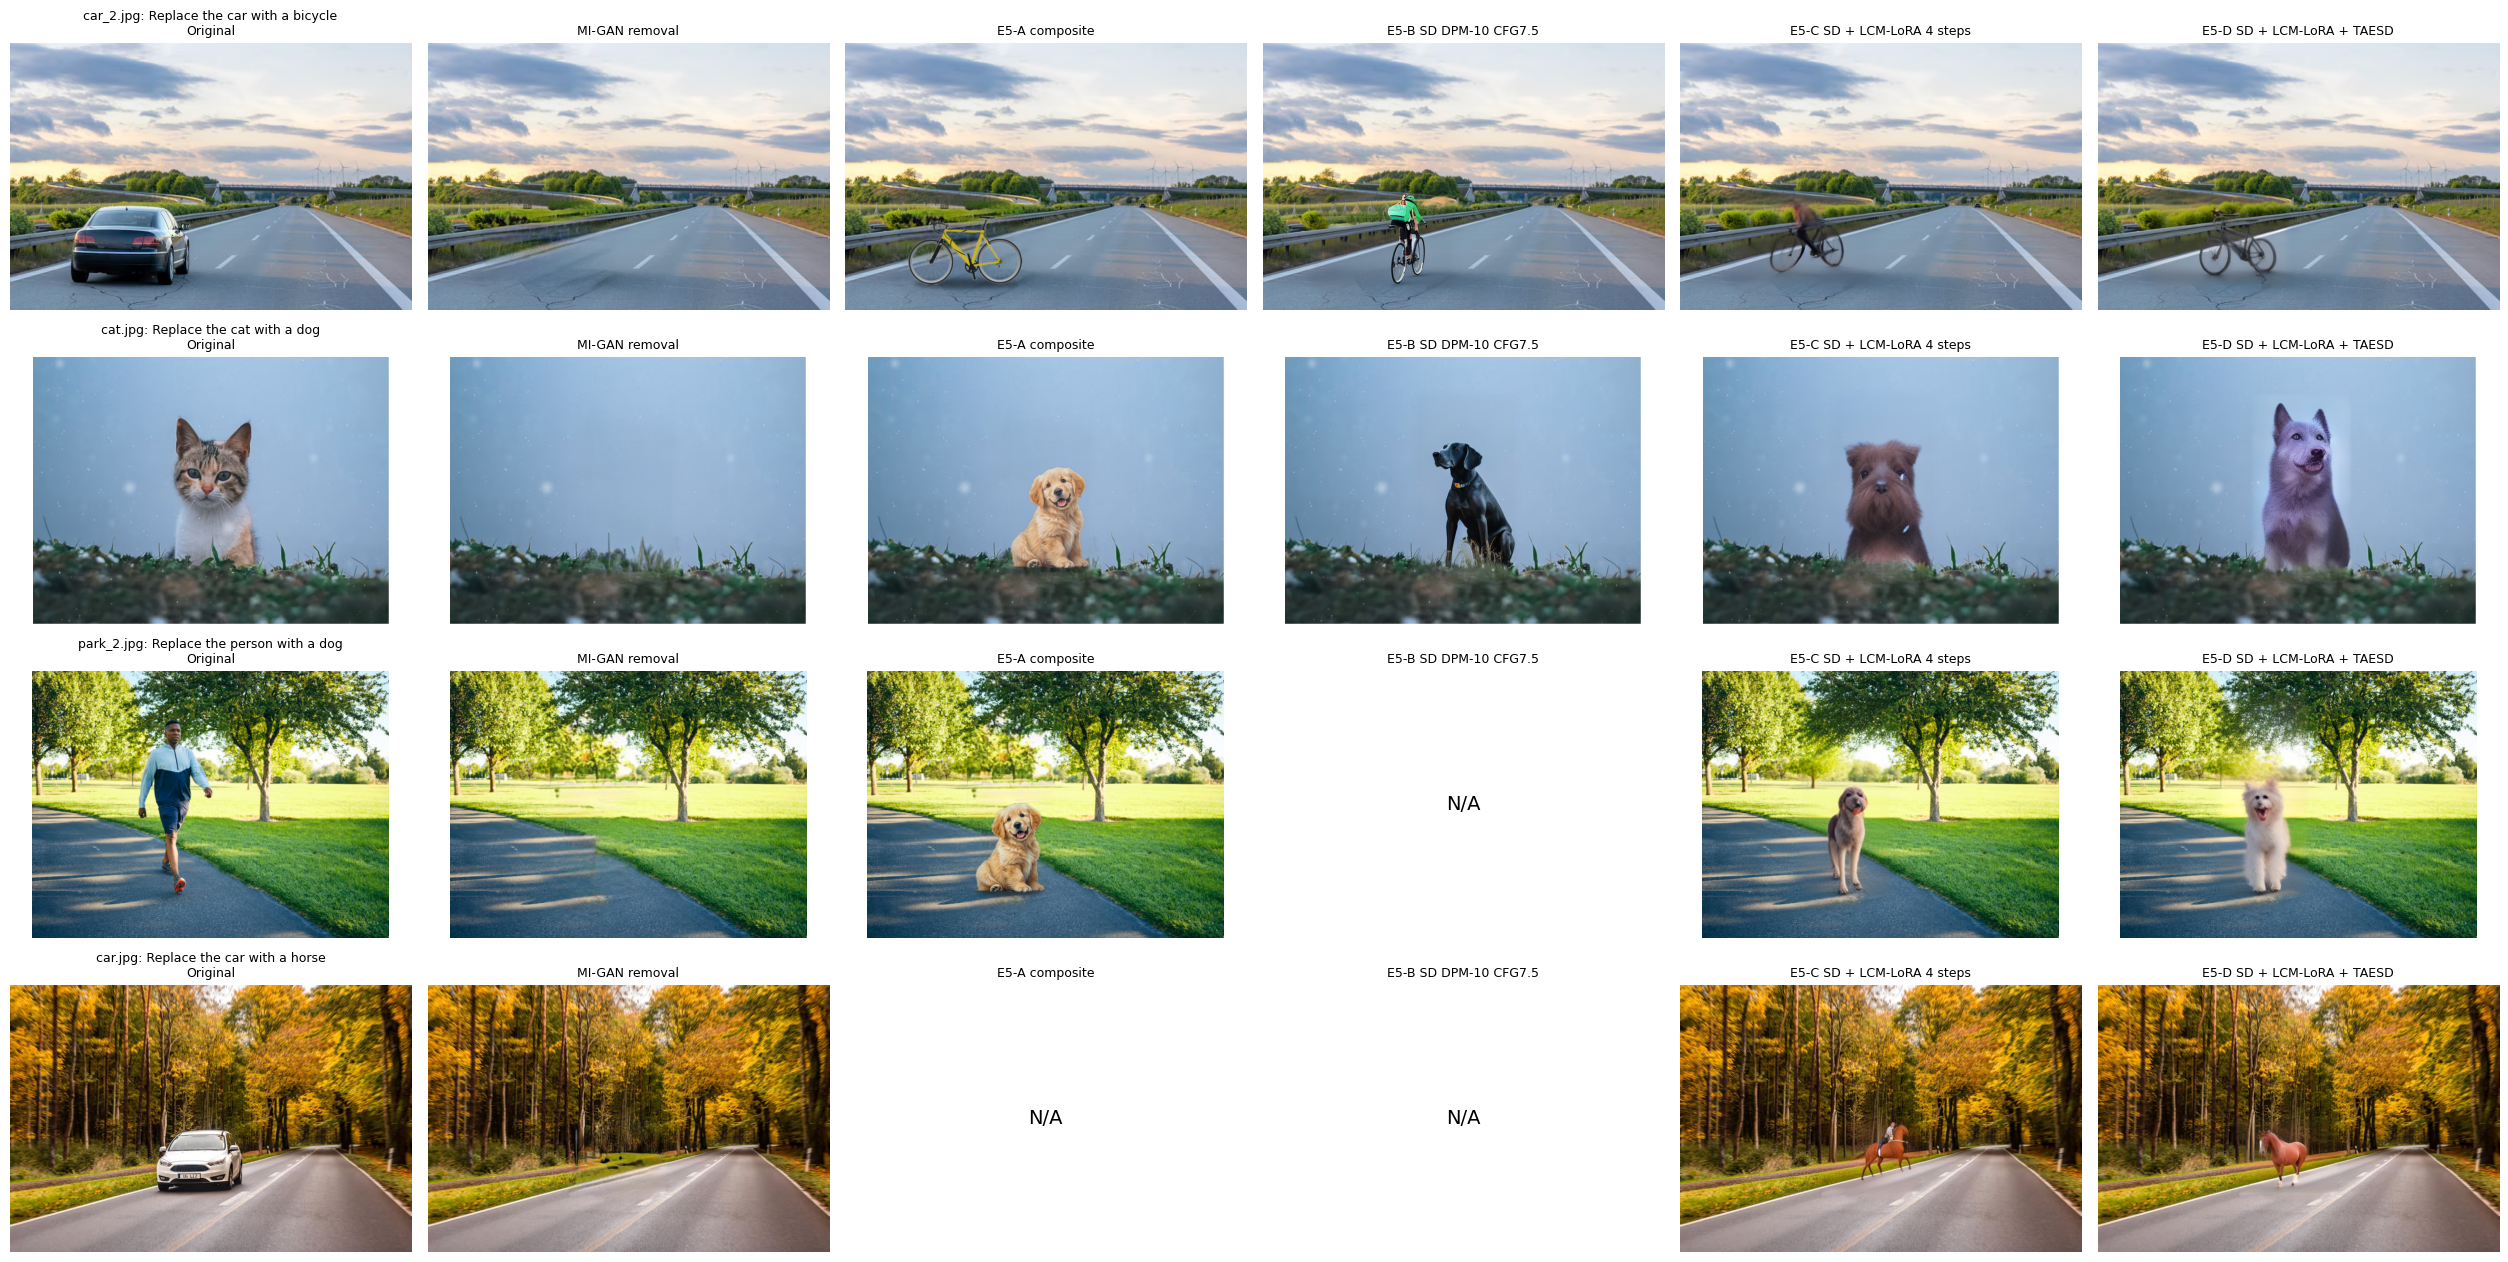

In [20]:
col_names = list(VARIANTS)
grid_rows, row_titles = [], []
for case in REPLACE_CASES:
    key = (case["image"], case["instruction"])
    grid_rows.append([read_image(case["image"]), CLEAN.get(key)] + [OUTPUTS.get(key + (v,)) for v in col_names])
    row_titles.append(f"{case['image']}: {case['instruction']}")

show_grid(grid_rows, ["Original", "MI-GAN removal"] + col_names, row_titles=row_titles, cell=4.2,
          save_as="e5_replacement_grid.jpg")

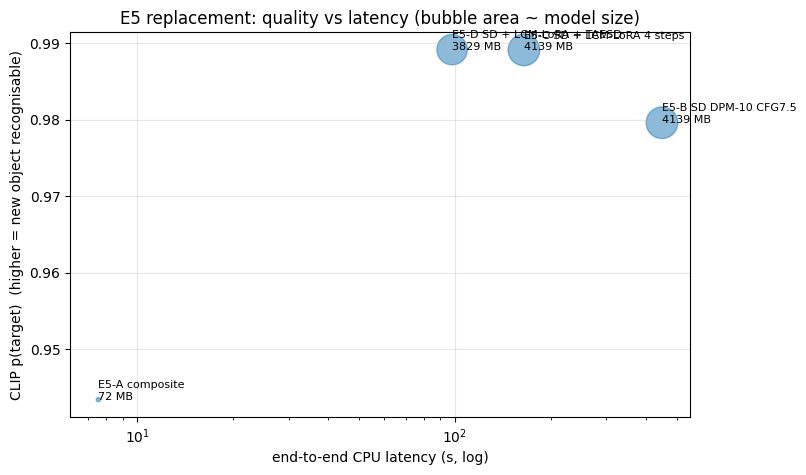

In [21]:
# Trade-off plot: latency vs CLIP target probability (bubble = model size)
if len(ok):
    s = e5_summary.dropna(subset=["total_sec"])
    plt.figure(figsize=(8, 5))
    plt.scatter(s["total_sec"], s["clip_p_target"], s=s["model_size_MB"] / 8, alpha=0.5)
    for name, r in s.iterrows():
        plt.annotate(f"{name}\n{r['model_size_MB']:.0f} MB", (r["total_sec"], r["clip_p_target"]), fontsize=8)
    plt.xscale("log")
    plt.xlabel("end-to-end CPU latency (s, log)")
    plt.ylabel("CLIP p(target)  (higher = new object recognisable)")
    plt.title("E5 replacement: quality vs latency (bubble area ~ model size)")
    plt.grid(alpha=0.3)
    plt.savefig(os.path.join(RESULTS_DIR, "e5_tradeoff.png"), dpi=120, bbox_inches="tight")
    plt.show()

## Observations (fill in after running)

* **Remove-first:** is the old object still visible in B, C or D? It shouldn't be, because MI-GAN has already erased it (compare with E2-A).
* **E5-A composite:** ~__ s total and no diffusion, but it only covers objects in the asset library (N/A for "horse"). Note any lighting or perspective mismatch.
* **E5-B → E5-C:** latency went from __ s to __ s (×__), and p(target) went from __ to __.
* **E5-C → E5-D:** TAESD saves __ s and __ MB. Visible quality loss: …
* **Failure cases:** …
* **Choice for E6:** remove with MI-GAN, then insert with LCM-SD + TAESD for text-defined targets. Keep compositing as a fast mode for objects in the library.